In [21]:
# IMPORTS AND SETUP
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt



In [22]:
# DATA LOADING
train_df = pd.read_csv("train_binary.csv")
test_df  = pd.read_csv("test_binary.csv")

print("Train Shape:", train_df.shape)
print("Test Shape :", test_df.shape)


Train Shape: (50000, 26)
Test Shape : (25000, 25)


In [23]:

X = train_df.iloc[:, :-1].values
y = train_df.iloc[:, -1].values.reshape(-1, 1)

X_test = test_df.values

np.random.seed(42)
indices = np.random.permutation(len(X))

split = int(0.8 * len(X))
train_idx, val_idx = indices[:split], indices[split:]

X_train, X_val = X[train_idx], X[val_idx]
y_train, y_val = y[train_idx], y[val_idx]



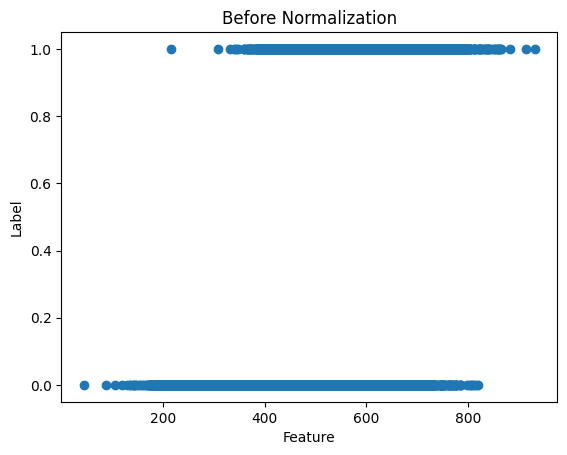

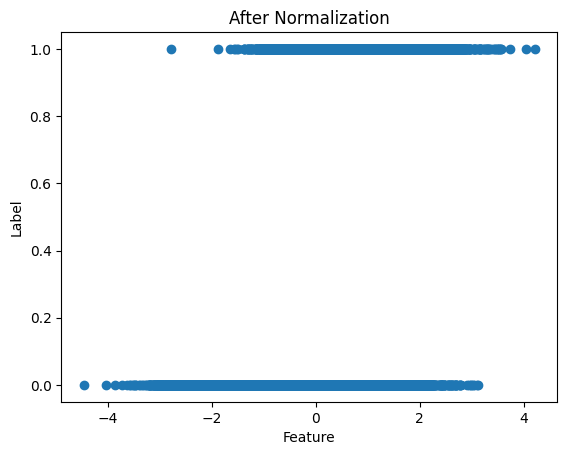

In [24]:
plt.figure()
plt.scatter(X_train[:, 0], y_train)
plt.title("Before Normalization")
plt.xlabel("Feature")
plt.ylabel("Label")
plt.show()

mean = X_train.mean(axis=0)
std  = X_train.std(axis=0) + 1e-8  # numerical stability

X_train = (X_train - mean) / std
X_val   = (X_val - mean) / std
X_test  = (X_test - mean) / std

X_train = np.c_[np.ones((X_train.shape[0], 1)), X_train]
X_val   = np.c_[np.ones((X_val.shape[0], 1)), X_val]
X_test  = np.c_[np.ones((X_test.shape[0], 1)), X_test]

plt.figure()
plt.scatter(X_train[:, 1], y_train)
plt.title("After Normalization")
plt.xlabel("Feature")
plt.ylabel("Label")
plt.show()


In [25]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def compute_loss(X, y, theta):
    m = len(y)
    h = sigmoid(X @ theta)
    epsilon = 1e-8
    return -(1/m) * np.sum(
        y * np.log(h + epsilon) + (1 - y) * np.log(1 - h + epsilon)
    )

def gradient_descent(X, y, Xv, yv, lr, epochs):
    m, n = X.shape
    theta = np.zeros((n, 1))

    train_losses, val_losses = [], []

    for _ in range(epochs):
        h = sigmoid(X @ theta)
        grad = (1/m) * (X.T @ (h - y))
        theta -= lr * grad

        train_losses.append(compute_loss(X, y, theta))
        val_losses.append(compute_loss(Xv, yv, theta))

    return theta, train_losses, val_losses




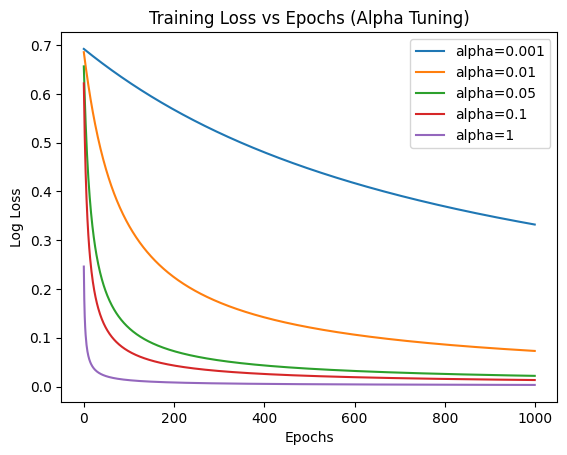

In [26]:
alphas = [0.001, 0.01, 0.05, 0.1 , 1 ]
epochs = 1000

plt.figure()
for alpha in alphas:
    _, losses, _ = gradient_descent(
        X_train, y_train, X_val, y_val, alpha, epochs
    )
    plt.plot(losses, label=f"alpha={alpha}")

plt.title("Training Loss vs Epochs (Alpha Tuning)")
plt.xlabel("Epochs")
plt.ylabel("Log Loss")
plt.legend()
plt.show()


In [27]:
best_alpha = 1
theta, train_losses, val_losses = gradient_descent(
    X_train, y_train, X_val, y_val, best_alpha, epochs
)

print("Training completed with alpha =", best_alpha)


Training completed with alpha = 1


In [28]:
train_pred = (sigmoid(X_train @ theta) >= 0.5).astype(int)
val_pred   = (sigmoid(X_val @ theta) >= 0.5).astype(int)

train_acc = np.mean(train_pred == y_train)
val_acc   = np.mean(val_pred == y_val)

print("Train Accuracy:", round(train_acc, 4))
print("Val Accuracy  :", round(val_acc, 4))


Train Accuracy: 0.9994
Val Accuracy  : 0.9997


In [29]:
TP = np.sum((val_pred == 1) & (y_val == 1))
TN = np.sum((val_pred == 0) & (y_val == 0))
FP = np.sum((val_pred == 1) & (y_val == 0))
FN = np.sum((val_pred == 0) & (y_val == 1))

print("\nConfusion Matrix (Validation)")
print(f"TP: {TP}  FP: {FP}")
print(f"FN: {FN}  TN: {TN}")



Confusion Matrix (Validation)
TP: 3032  FP: 0
FN: 3  TN: 6965


In [30]:
test_probs = sigmoid(X_test @ theta)
test_preds = (test_probs >= 0.5).astype(int)

submission = pd.DataFrame({"Prediction": test_preds.flatten()})
submission.to_csv("logistic_predictions.csv", index=False)

print("✅ Submission file saved: logistic_predictions.csv")


✅ Submission file saved: logistic_predictions.csv
